<a href="https://colab.research.google.com/github/TBDA-Classes/2026G3/blob/main/T33.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import pandas as pd

df = pd.read_csv("/content/cedint_f1_model_ready.csv")

print("Shape:", df.shape)

print("\nSeries available:")
print(
    df.groupby(["zone", "load_type"])
      .size()
      .reset_index(name="rows")
      .to_string(index=False)
)

print("\nSplits:")
print(df["split"].value_counts())

In [ ]:
print(df.columns.tolist())

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import pandas as pd

# Load data
df = pd.read_csv("/content/cedint_f1_model_ready.csv")
weather = pd.read_csv("/content/openmeteo_madrid_hourly.csv")

# Parse timestamps
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], utc=True)

# Select NE HVAC
ne_hvac = df[
    (df["zone_code"] == "NE") &
    (df["load_type"] == "HVAC")
].copy()

# Merge weather
ne_hvac = ne_hvac.merge(
    weather,
    left_on="timestamp_utc",
    right_on="timestamp",
    how="left"
)

print("Shape NE HVAC:", ne_hvac.shape)

print("\nSplit counts:")
print(ne_hvac["split"].value_counts())

print("\nWeather missing values:")
print(ne_hvac[["w_temp", "w_hum", "w_rad", "w_wind"]].isna().sum())

print("\nFirst rows:")
print(
    ne_hvac[
        [
            "timestamp_utc",
            "energy_wh_model",
            "w_temp",
            "w_hum",
            "w_rad",
            "w_wind"
        ]
    ].head()
)

In [ ]:
import pandas as pd

# Load data
df = pd.read_csv("/content/cedint_f1_model_ready.csv")
weather = pd.read_csv("/content/openmeteo_madrid_hourly.csv")

# Parse timestamps
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], utc=True)

# Select 1NE HVAC
ne_hvac = df[
    (df["zone_code"] == "1NE") &
    (df["load_type"] == "HVAC")
].copy()

# Merge weather
ne_hvac = ne_hvac.merge(
    weather,
    left_on="timestamp_utc",
    right_on="timestamp",
    how="left"
)

print("Shape NE HVAC:", ne_hvac.shape)

print("\nSplit counts:")
print(ne_hvac["split"].value_counts())

print("\nWeather missing values:")
print(ne_hvac[["w_temp", "w_hum", "w_rad", "w_wind"]].isna().sum())

print("\nFirst rows:")
print(
    ne_hvac[
        [
            "timestamp_utc",
            "energy_wh_model",
            "w_temp",
            "w_hum",
            "w_rad",
            "w_wind"
        ]
    ].head()
)


In [ ]:
import pandas as pd

df = pd.read_csv("/content/cedint_f1_model_ready.csv")

print("Shape:", df.shape)

print("\nSeries available:")
print(
    df.groupby(["zone", "load_type"])
      .size()
      .reset_index(name="rows")
      .to_string(index=False)
)

print("\nSplits:")
print(df["split"].value_counts())

In [ ]:
feature_cols = [
    "hod", "dow", "month",
    "is_weekend", "is_holiday", "hol_prev", "hol_next",
    "is_august", "covid",
    "hod_sin", "hod_cos", "doy_sin", "doy_cos",
    "w_temp", "w_hum", "w_rad", "w_wind",
    "hdd18", "cdd24", "w_temp_roll24",
    "w_temp_l1", "w_temp_l2", "w_temp_l3",
    "w_temp_l4", "w_temp_l5", "w_temp_l6",
    "lag_24", "lag_48", "lag_72", "lag_168", "lag_336",
    "roll_mean_24", "roll_mean_168", "roll_sd_24",
    "same_hour_mean_7d",
    "temp_c_l24", "temp_c_l168",
    "hum_pct_l24", "hum_pct_l168",
    "lum_lux_l24", "lum_lux_l168",
    "occupancy_l24", "occupancy_l168"
]

existing_features = [c for c in feature_cols if c in data.columns]
missing_features = [c for c in feature_cols if c not in data.columns]

print("Expected features:", len(feature_cols))
print("Available features:", len(existing_features))
print("Missing features:", missing_features)

In [ ]:
import numpy as np
import pandas as pd

data = ne_hvac.copy()
data = data.sort_values("timestamp_utc").reset_index(drop=True)

# Local time
local_time = data["timestamp_utc"].dt.tz_convert("Europe/Madrid")

# Calendar
data["hod"] = local_time.dt.hour
data["dow"] = local_time.dt.dayofweek
data["month"] = local_time.dt.month
data["doy"] = local_time.dt.dayofyear

data["is_august"] = data["is_august_low_use"].astype(int)
data["covid"] = data["flag_covid_2020"].astype(int)

# Holiday previous / next
data["date_local"] = local_time.dt.date

holiday_by_date = (
    data.groupby("date_local")["is_holiday"]
        .max()
        .to_dict()
)

data["hol_prev"] = [
    int(holiday_by_date.get(d - pd.Timedelta(days=1), 0))
    for d in data["date_local"]
]

data["hol_next"] = [
    int(holiday_by_date.get(d + pd.Timedelta(days=1), 0))
    for d in data["date_local"]
]

# Cyclical calendar features
data["hod_sin"] = np.sin(2 * np.pi * data["hod"] / 24)
data["hod_cos"] = np.cos(2 * np.pi * data["hod"] / 24)

data["doy_sin"] = np.sin(2 * np.pi * data["doy"] / 365.25)
data["doy_cos"] = np.cos(2 * np.pi * data["doy"] / 365.25)

# Weather features
data["hdd18"] = np.maximum(18 - data["w_temp"], 0)
data["cdd24"] = np.maximum(data["w_temp"] - 24, 0)

data["w_temp_roll24"] = data["w_temp"].rolling(24).mean()

for k in range(1, 7):
    data[f"w_temp_l{k}"] = data["w_temp"].shift(k)

# Energy lags
for k in [24, 48, 72, 168, 336]:
    data[f"lag_{k}"] = data["energy_wh_model"].shift(k)

y24 = data["energy_wh_model"].shift(24)

data["roll_mean_24"] = y24.rolling(24).mean()
data["roll_mean_168"] = y24.rolling(168).mean()
data["roll_sd_24"] = y24.rolling(24).std()

same_hour_lags = pd.concat(
    [data["energy_wh_model"].shift(24 * k) for k in range(1, 8)],
    axis=1
)

data["same_hour_mean_7d"] = same_hour_lags.mean(axis=1)

# Indoor variables lagged
for var in ["temp_c", "hum_pct", "lum_lux", "occupancy"]:
    data[f"{var}_l24"] = data[var].shift(24)
    data[f"{var}_l168"] = data[var].shift(168)

print("Feature creation complete.")
print("Shape:", data.shape)

In [ ]:
import pandas as pd

# Load files
df = pd.read_csv("/content/cedint_f1_model_ready.csv")
weather = pd.read_csv("/content/openmeteo_madrid_hourly.csv")

# Parse timestamps
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], utc=True)

# Select NE HVAC
ne_hvac = df[
    (df["zone_code"] == "1NE") &
    (df["load_type"] == "HVAC")
].copy()

# Merge with weather
ne_hvac = ne_hvac.merge(
    weather,
    left_on="timestamp_utc",
    right_on="timestamp",
    how="left"
)

print("Shape NE HVAC:", ne_hvac.shape)
print(ne_hvac["split"].value_counts())

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import os
print(os.listdir("/content"))

In [ ]:
import pandas as pd

df = pd.read_csv("/content/cedint_f1_model_ready.csv")
weather = pd.read_csv("/content/openmeteo_madrid_hourly.csv")

df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], utc=True)

ne_hvac = df[
    (df["zone_code"] == "1NE") &
    (df["load_type"] == "HVAC")
].copy()

ne_hvac = ne_hvac.merge(
    weather,
    left_on="timestamp_utc",
    right_on="timestamp",
    how="left"
)

print("Shape NE HVAC:", ne_hvac.shape)
print("\nSplit counts:")
print(ne_hvac["split"].value_counts())

In [ ]:
import numpy as np
import pandas as pd

data = ne_hvac.copy()
data = data.sort_values("timestamp_utc").reset_index(drop=True)

# Local time
local_time = data["timestamp_utc"].dt.tz_convert("Europe/Madrid")

# Calendar features
data["hod"] = local_time.dt.hour
data["dow"] = local_time.dt.dayofweek
data["month"] = local_time.dt.month
data["doy"] = local_time.dt.dayofyear

data["is_august"] = data["is_august_low_use"].astype(int)
data["covid"] = data["flag_covid_2020"].astype(int)

# Local date
data["date_local"] = local_time.dt.date

# Previous/next holiday
holiday_by_date = (
    data.groupby("date_local")["is_holiday"]
        .max()
        .to_dict()
)

data["hol_prev"] = [
    int(holiday_by_date.get(d - pd.Timedelta(days=1), 0))
    for d in data["date_local"]
]

data["hol_next"] = [
    int(holiday_by_date.get(d + pd.Timedelta(days=1), 0))
    for d in data["date_local"]
]

# Cyclical calendar
data["hod_sin"] = np.sin(2 * np.pi * data["hod"] / 24)
data["hod_cos"] = np.cos(2 * np.pi * data["hod"] / 24)

data["doy_sin"] = np.sin(2 * np.pi * data["doy"] / 365.25)
data["doy_cos"] = np.cos(2 * np.pi * data["doy"] / 365.25)

# Weather-derived features
data["hdd18"] = np.maximum(18 - data["w_temp"], 0)
data["cdd24"] = np.maximum(data["w_temp"] - 24, 0)
data["w_temp_roll24"] = data["w_temp"].rolling(24).mean()

# Weather lags 1-6h
for k in range(1, 7):
    data[f"w_temp_l{k}"] = data["w_temp"].shift(k)

# Energy lags
for k in [24, 48, 72, 168, 336]:
    data[f"lag_{k}"] = data["energy_wh_model"].shift(k)

# Rolling energy statistics
y24 = data["energy_wh_model"].shift(24)

data["roll_mean_24"] = y24.rolling(24).mean()
data["roll_mean_168"] = y24.rolling(168).mean()
data["roll_sd_24"] = y24.rolling(24).std()

# Mean of same hour over previous 7 days
same_hour_lags = pd.concat(
    [data["energy_wh_model"].shift(24 * k) for k in range(1, 8)],
    axis=1
)

data["same_hour_mean_7d"] = same_hour_lags.mean(axis=1)

# Indoor driver lags
for var in ["temp_c", "hum_pct", "lum_lux", "occupancy"]:
    data[f"{var}_l24"] = data[var].shift(24)
    data[f"{var}_l168"] = data[var].shift(168)

print("Feature creation complete.")
print("Shape:", data.shape)

In [ ]:
feature_cols = [
    "hod", "dow", "month",
    "is_weekend", "is_holiday", "hol_prev", "hol_next",
    "is_august", "covid",
    "hod_sin", "hod_cos", "doy_sin", "doy_cos",
    "w_temp", "w_hum", "w_rad", "w_wind",
    "hdd18", "cdd24", "w_temp_roll24",
    "w_temp_l1", "w_temp_l2", "w_temp_l3",
    "w_temp_l4", "w_temp_l5", "w_temp_l6",
    "lag_24", "lag_48", "lag_72", "lag_168", "lag_336",
    "roll_mean_24", "roll_mean_168", "roll_sd_24",
    "same_hour_mean_7d",
    "temp_c_l24", "temp_c_l168",
    "hum_pct_l24", "hum_pct_l168",
    "lum_lux_l24", "lum_lux_l168",
    "occupancy_l24", "occupancy_l168"
]

existing_features = [c for c in feature_cols if c in data.columns]
missing_features = [c for c in feature_cols if c not in data.columns]

print("Expected:", len(feature_cols))
print("Available:", len(existing_features))
print("Missing:", missing_features)

In [ ]:
# Train and validation sets
train = data[
    (data["split"] == "train") &
    (data["include_train"] == 1) &
    (data["energy_wh_model"].notna())
].copy()

valid = data[
    (data["split"] == "validation") &
    (data["include_eval"] == 1) &
    (data["energy_wh_model"].notna())
].copy()

# Keep only rows where all model features are available
train = train.dropna(subset=feature_cols)
valid = valid.dropna(subset=feature_cols)

X_train = train[feature_cols]
y_train = train["energy_wh_model"]

X_valid = valid[feature_cols]
y_valid = valid["energy_wh_model"]

print("Train rows:", len(train))
print("Validation rows:", len(valid))
print("Number of features:", X_train.shape[1])

print("\nTrain period:")
print(train["timestamp_utc"].min(), "to", train["timestamp_utc"].max())

print("\nValidation period:")
print(valid["timestamp_utc"].min(), "to", valid["timestamp_utc"].max())

In [ ]:
# Start from rows belonging to train and validation
train0 = data[
    (data["split"] == "train") &
    (data["include_train"] == 1) &
    (data["energy_wh_model"].notna())
].copy()

valid0 = data[
    (data["split"] == "validation") &
    (data["energy_wh_model"].notna())
].copy()

# Exactly as T29: remove features that contain no usable value in training
usable_features = [
    c for c in feature_cols
    if c in train0.columns and train0[c].notna().any()
]

removed_features = [
    c for c in feature_cols
    if c not in usable_features
]

print("Train before dropna:", len(train0))
print("Validation before dropna:", len(valid0))

print("\nUsable features:", len(usable_features))

print("\nFeatures removed because completely empty in NE:")
print(removed_features)

In [ ]:
# Keep only rows with complete values for the usable features
train = train0.dropna(subset=usable_features).copy()
valid = valid0.dropna(subset=usable_features).copy()

X_train = train[usable_features]
y_train = train["energy_wh_model"]

X_valid = valid[usable_features]
y_valid = valid["energy_wh_model"]

print("Final train rows:", len(train))
print("Final validation rows:", len(valid))
print("Number of model features:", X_train.shape[1])

print("\nTrain period:")
print(train["timestamp_utc"].min(), "to", train["timestamp_utc"].max())

print("\nValidation period:")
print(valid["timestamp_utc"].min(), "to", valid["timestamp_utc"].max())

In [ ]:
# Use all train/validation rows with a valid target.
# LightGBM can handle missing feature values (NaN).

train = train0.copy()
valid = valid0.copy()

X_train = train[usable_features]
y_train = train["energy_wh_model"]

X_valid = valid[usable_features]
y_valid = valid["energy_wh_model"]

print("Train rows:", len(train))
print("Validation rows:", len(valid))
print("Number of features:", len(usable_features))

print("\nMissing values in X_train:")
print(X_train.isna().sum().sort_values(ascending=False).head(10))

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
print(result.keys())

for key, value in result.items():
    print("\nKEY:", key)
    print("TYPE:", type(value))
    print(value)

In [ ]:
!pip install pyreadr -q

import pyreadr

result = pyreadr.read_r("/content/T29_best_params (1).rds")

print("File loaded")
print(result.keys())

In [ ]:
!Rscript -e 'x <- readRDS("/content/T29_best_params (1).rds"); print(names(x)); str(x, max.level=2)'

In [ ]:
!Rscript -e 'x <- readRDS("/content/T29_best_params (1).rds"); print(x[["1NE HVAC"]]$lgb); print(x[["1NE HVAC"]]$lgb_nrounds)'

In [ ]:
!pip install lightgbm -q

import lightgbm as lgb

model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=50,
    num_leaves=127,
    learning_rate=0.1,
    min_child_samples=20,      # equivalent to min_data_in_leaf
    colsample_bytree=0.6,      # feature_fraction
    subsample=0.7,             # bagging_fraction
    subsample_freq=1,
    reg_lambda=50,             # lambda_l2
    random_state=42,
    verbosity=-1
)

model.fit(
    X_train,
    y_train
)

print("LightGBM trained successfully.")
print("Features used:", model.n_features_in_)

In [ ]:
!pip install shap -q

import shap

# Create SHAP explainer for the trained LightGBM model
explainer = shap.TreeExplainer(model)

# Use validation data for explanation
shap_values = explainer.shap_values(X_valid)

print("SHAP values computed.")
print("Shape:", shap_values.shape)

In [ ]:
import numpy as np
import pandas as pd

# Mean absolute SHAP value = global feature importance
shap_importance = pd.DataFrame({
    "feature": X_valid.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(shap_importance.head(15))


In [ ]:
import shap
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values,
    X_valid,
    plot_type="bar",
    max_display=15
)

plt.show()

In [ ]:
shap.summary_plot(
    shap_values,
    X_valid,
    max_display=15
)


The SHAP analysis shows that the LightGBM forecast for 1NE HVAC is mainly driven by recent energy-consumption patterns. High recent consumption, especially the 24-hour rolling mean and the previous-day load, increases the predicted HVAC demand. Seasonal and outdoor-temperature variables also contribute, but their impact is smaller.

In [ ]:
shap.dependence_plot(
    "roll_mean_24",
    shap_values,
    X_valid,
    interaction_index=None
)

The dependence plot confirms that recent consumption has a strong nonlinear effect on the forecast. Low 24-hour rolling consumption decreases the predicted HVAC demand, while higher recent consumption strongly increases it.”

In [ ]:
shap.dependence_plot(
    "w_temp_roll24",
    shap_values,
    X_valid,
    interaction_index=None
)

The SHAP dependence plot shows a clearly nonlinear temperature effect. Moderate outdoor temperatures tend to reduce the predicted HVAC demand, while very high temperatures, especially above about 30°C, strongly increase the forecast.

In [ ]:
# Final SHAP importance table

final_shap_table = shap_importance.copy()

final_shap_table["rank"] = range(1, len(final_shap_table) + 1)

final_shap_table = final_shap_table[
    ["rank", "feature", "mean_abs_shap"]
]

# Save CSV
final_shap_table.to_csv(
    "/content/T33_NE_HVAC_SHAP_importance.csv",
    index=False
)

print("T33 SHAP importance table saved.")
print("\nTop 15 features:")
print(final_shap_table.head(15).to_string(index=False))

In [ ]:
import pandas as pd
import numpy as np

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import shap
import matplotlib.pyplot as plt

# Carica il dataset
df = pd.read_csv("cedint_f1_model_ready.csv")

df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])

print(df.shape)
print(df.columns.tolist())

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd
import numpy as np

from sklearn.ensemble import GradientBoostingRegressor
import shap
import matplotlib.pyplot as plt

df = pd.read_csv("cedint_f1_model_ready.csv")
df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])

print(df.shape)
print(df.columns.tolist())

In [ ]:
# Filtra la serie NE HVAC
ne_hvac = df[
    (df["zone"] == "NE") &
    (df["load_type"] == "HVAC")
].copy()

ne_hvac = ne_hvac.sort_values("timestamp_local").reset_index(drop=True)

# Ricrea le feature usate nel notebook GBM
ne_hvac["energy_lag_24"] = ne_hvac["energy_wh_model"].shift(24)
ne_hvac["energy_lag_168"] = ne_hvac["energy_wh_model"].shift(168)

ne_hvac["temp_lag1"] = ne_hvac["temp_c"].shift(1)
ne_hvac["temp_lag2"] = ne_hvac["temp_c"].shift(2)

ne_hvac["roll_mean_24"] = ne_hvac["energy_wh_model"].rolling(window=24).mean()

ne_hvac["dh_heat"] = (18 - ne_hvac["temp_c"]).clip(lower=0)
ne_hvac["dh_cool"] = (ne_hvac["temp_c"] - 24).clip(lower=0)

# Come nel codice originale
ne_hvac = ne_hvac.dropna(
    subset=["energy_wh_model", "energy_lag_168", "roll_mean_24"]
).copy()

features = [
    "hour_local",
    "dayofweek_local",
    "month_local",
    "is_weekend",
    "is_holiday",
    "temp_c",
    "dh_cool",
    "dh_heat",
    "temp_lag1",
    "temp_lag2",
    "occupancy",
    "lum_lux",
    "energy_lag_24",
    "energy_lag_168",
    "roll_mean_24"
]

print("NE HVAC shape:", ne_hvac.shape)
print("\nSplit counts:")
print(ne_hvac["split"].value_counts())

print("\nMissing values in features:")
print(ne_hvac[features].isna().sum())

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Stesso comportamento del notebook originale
X = ne_hvac[features].fillna(0)
y = ne_hvac["energy_wh_model"]

# Training ufficiale
train_mask = ne_hvac["include_train"] == 1

X_train = X[train_mask]
y_train = y[train_mask]

# Validation 2022-H2
val_mask = (
    (ne_hvac["split"] == "validation") &
    (ne_hvac["include_eval"] == 1)
)

X_val = X[val_mask]
y_val = y[val_mask]

# Stesso modello di Joos
gbm = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

gbm.fit(X_train, y_train)

# Prediction sulla validation
pred_val = gbm.predict(X_val)

# Metriche
mae = mean_absolute_error(y_val, pred_val)
rmse = np.sqrt(mean_squared_error(y_val, pred_val))
cv_rmse = 100 * rmse / y_val.mean()
nmbe = 100 * np.sum(y_val - pred_val) / (len(y_val) * y_val.mean())

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print()
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"CV(RMSE): {cv_rmse:.2f}%")
print(f"NMBE: {nmbe:.2f}%")

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# SHAP explainer
explainer = shap.Explainer(gbm, X_train)

# SHAP values sulla validation
shap_values = explainer(X_val)

print("SHAP values computed.")
print("Shape:", shap_values.values.shape)

In [ ]:
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": X_val.columns,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

shap_importance["rank"] = shap_importance.index + 1

print(shap_importance[["rank", "feature", "mean_abs_shap"]].to_string(index=False))

In [ ]:
shap.plots.scatter(
    shap_values[:, "roll_mean_24"],
    color=shap_values[:, "energy_lag_24"]
)

In [ ]:
shap.plots.scatter(
    shap_values[:, "energy_lag_24"],
    color=shap_values[:, "roll_mean_24"]
)

In [ ]:
shap.plots.scatter(
    shap_values[:, "hour_local"],
    color=shap_values[:, "roll_mean_24"]
)

In [ ]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [ ]:
# =========================
# T33 - NW PLUGS & SOCKETS
# =========================

nw_plugs = df[
    (df["zone"] == "NW") &
    (df["load_type"] == "Plugs & Sockets")
].copy()

nw_plugs = nw_plugs.sort_values("timestamp_local").reset_index(drop=True)

# Stesse feature del GBM del team
nw_plugs["energy_lag_24"] = nw_plugs["energy_wh_model"].shift(24)
nw_plugs["energy_lag_168"] = nw_plugs["energy_wh_model"].shift(168)

nw_plugs["temp_lag1"] = nw_plugs["temp_c"].shift(1)
nw_plugs["temp_lag2"] = nw_plugs["temp_c"].shift(2)

nw_plugs["roll_mean_24"] = (
    nw_plugs["energy_wh_model"]
    .rolling(window=24)
    .mean()
)

nw_plugs["dh_heat"] = (18 - nw_plugs["temp_c"]).clip(lower=0)
nw_plugs["dh_cool"] = (nw_plugs["temp_c"] - 24).clip(lower=0)

nw_plugs = nw_plugs.dropna(
    subset=["energy_wh_model", "energy_lag_168", "roll_mean_24"]
).copy()

features_plugs = [
    "hour_local",
    "dayofweek_local",
    "month_local",
    "is_weekend",
    "is_holiday",
    "temp_c",
    "dh_cool",
    "dh_heat",
    "temp_lag1",
    "temp_lag2",
    "occupancy",
    "lum_lux",
    "energy_lag_24",
    "energy_lag_168",
    "roll_mean_24"
]

print("NW Plugs shape:", nw_plugs.shape)

print("\nSplit counts:")
print(nw_plugs["split"].value_counts())

print("\nMissing values in features:")
print(nw_plugs[features_plugs].isna().sum())

In [ ]:
# =========================
# T33 - NW PLUGS & SOCKETS
# =========================

nw_plugs = df[
    (df["zone"] == "NW") &
    (df["load_type"] == "Plugs & Sockets")
].copy()

nw_plugs = nw_plugs.sort_values("timestamp_local").reset_index(drop=True)

# Stesse feature del GBM del team
nw_plugs["energy_lag_24"] = nw_plugs["energy_wh_model"].shift(24)
nw_plugs["energy_lag_168"] = nw_plugs["energy_wh_model"].shift(168)

nw_plugs["temp_lag1"] = nw_plugs["temp_c"].shift(1)
nw_plugs["temp_lag2"] = nw_plugs["temp_c"].shift(2)

nw_plugs["roll_mean_24"] = (
    nw_plugs["energy_wh_model"]
    .rolling(window=24)
    .mean()
)

nw_plugs["dh_heat"] = (18 - nw_plugs["temp_c"]).clip(lower=0)
nw_plugs["dh_cool"] = (nw_plugs["temp_c"] - 24).clip(lower=0)

nw_plugs = nw_plugs.dropna(
    subset=["energy_wh_model", "energy_lag_168", "roll_mean_24"]
).copy()

features_plugs = [
    "hour_local",
    "dayofweek_local",
    "month_local",
    "is_weekend",
    "is_holiday",
    "temp_c",
    "dh_cool",
    "dh_heat",
    "temp_lag1",
    "temp_lag2",
    "occupancy",
    "lum_lux",
    "energy_lag_24",
    "energy_lag_168",
    "roll_mean_24"
]

print("NW Plugs shape:", nw_plugs.shape)

print("\nSplit counts:")
print(nw_plugs["split"].value_counts())

print("\nMissing values in features:")
print(nw_plugs[features_plugs].isna().sum())

NW Plugs shape: (25548, 38)

Split counts:
split
train         17993
validation     3877
test_2023      1345
test_2025      1191
unused         1142
Name: count, dtype: int64

Missing values in features:
hour_local           0
dayofweek_local      0
month_local          0
is_weekend           0
is_holiday           0
temp_c             182
dh_cool            182
dh_heat            182
temp_lag1          167
temp_lag2          152
occupancy          182
lum_lux            182
energy_lag_24       14
energy_lag_168       0
roll_mean_24         0
dtype: int64


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X = nw_plugs[features_plugs].fillna(0)
y = nw_plugs["energy_wh_model"]

# Training
train_mask = nw_plugs["include_train"] == 1
X_train_plugs = X[train_mask]
y_train_plugs = y[train_mask]

# Validation
val_mask = (
    (nw_plugs["split"] == "validation") &
    (nw_plugs["include_eval"] == 1)
)

X_val_plugs = X[val_mask]
y_val_plugs = y[val_mask]

# Stesso GBM del team
gbm_plugs = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

gbm_plugs.fit(X_train_plugs, y_train_plugs)

pred_val_plugs = gbm_plugs.predict(X_val_plugs)

mae = mean_absolute_error(y_val_plugs, pred_val_plugs)
rmse = np.sqrt(mean_squared_error(y_val_plugs, pred_val_plugs))
cv_rmse = 100 * rmse / y_val_plugs.mean()
nmbe = 100 * np.sum(y_val_plugs - pred_val_plugs) / (
    len(y_val_plugs) * y_val_plugs.mean()
)

print("Training rows:", len(X_train_plugs))
print("Validation rows:", len(X_val_plugs))
print()
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"CV(RMSE): {cv_rmse:.2f}%")
print(f"NMBE: {nmbe:.2f}%")

Training rows: 17393
Validation rows: 3871

MAE: 326.43
RMSE: 581.09
CV(RMSE): 42.63%
NMBE: 1.12%


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X = nw_plugs[features_plugs].fillna(0)
y = nw_plugs["energy_wh_model"]

# Training
train_mask = nw_plugs["include_train"] == 1
X_train_plugs = X[train_mask]
y_train_plugs = y[train_mask]

# Validation
val_mask = (
    (nw_plugs["split"] == "validation") &
    (nw_plugs["include_eval"] == 1)
)

X_val_plugs = X[val_mask]
y_val_plugs = y[val_mask]

# Stesso GBM del team
gbm_plugs = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

gbm_plugs.fit(X_train_plugs, y_train_plugs)

pred_val_plugs = gbm_plugs.predict(X_val_plugs)

mae = mean_absolute_error(y_val_plugs, pred_val_plugs)
rmse = np.sqrt(mean_squared_error(y_val_plugs, pred_val_plugs))
cv_rmse = 100 * rmse / y_val_plugs.mean()
nmbe = 100 * np.sum(y_val_plugs - pred_val_plugs) / (
    len(y_val_plugs) * y_val_plugs.mean()
)

print("Training rows:", len(X_train_plugs))
print("Validation rows:", len(X_val_plugs))
print()
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"CV(RMSE): {cv_rmse:.2f}%")
print(f"NMBE: {nmbe:.2f}%")

Training rows: 17393
Validation rows: 3871

MAE: 326.43
RMSE: 581.09
CV(RMSE): 42.63%
NMBE: 1.12%


In [ ]:
import shap
import pandas as pd
import numpy as np

background = X_train_plugs.sample(
    min(100, len(X_train_plugs)),
    random_state=42
)

explainer_plugs = shap.Explainer(gbm_plugs, background)
shap_values_plugs = explainer_plugs(X_val_plugs)

print("SHAP values computed.")
print("Shape:", shap_values_plugs.values.shape)

ExplainerError: Additivity check failed in TreeExplainer! Please ensure the data matrix you passed to the explainer is the same shape that the model was trained on. If your data shape is correct then please report this on GitHub. This check failed because for one of the samples the sum of the SHAP values was 1658.287655, while the model output was 1616.370847. If this difference is acceptable you can set check_additivity=False to disable this check.

In [ ]:
explainer_plugs = shap.TreeExplainer(gbm_plugs)

shap_values_array = explainer_plugs.shap_values(
    X_val_plugs,
    check_additivity=False
)

# Ricreiamo un oggetto Explanation, così possiamo usare i plot moderni di SHAP
shap_values_plugs = shap.Explanation(
    values=shap_values_array,
    base_values=np.repeat(explainer_plugs.expected_value, len(X_val_plugs)),
    data=X_val_plugs.values,
    feature_names=X_val_plugs.columns.tolist()
)

print("SHAP values computed.")
print("Shape:", shap_values_plugs.values.shape)

SHAP values computed.
Shape: (3871, 15)


In [ ]:
shap_importance_plugs = pd.DataFrame({
    "feature": X_val_plugs.columns,
    "mean_abs_shap": np.abs(shap_values_plugs.values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

shap_importance_plugs["rank"] = shap_importance_plugs.index + 1

print(
    shap_importance_plugs[
        ["rank", "feature", "mean_abs_shap"]
    ].to_string(index=False)
)

 rank         feature  mean_abs_shap
    1    roll_mean_24     639.447868
    2       temp_lag2     160.237664
    3   energy_lag_24     116.909718
    4          temp_c      73.734582
    5         lum_lux      73.528064
    6      hour_local      58.654677
    7  energy_lag_168      55.353577
    8         dh_heat      40.767601
    9 dayofweek_local      15.932228
   10      is_weekend      15.561571
   11       temp_lag1      14.852328
   12     month_local       5.795923
   13       occupancy       2.594627
   14      is_holiday       2.037124
   15         dh_cool       0.854289


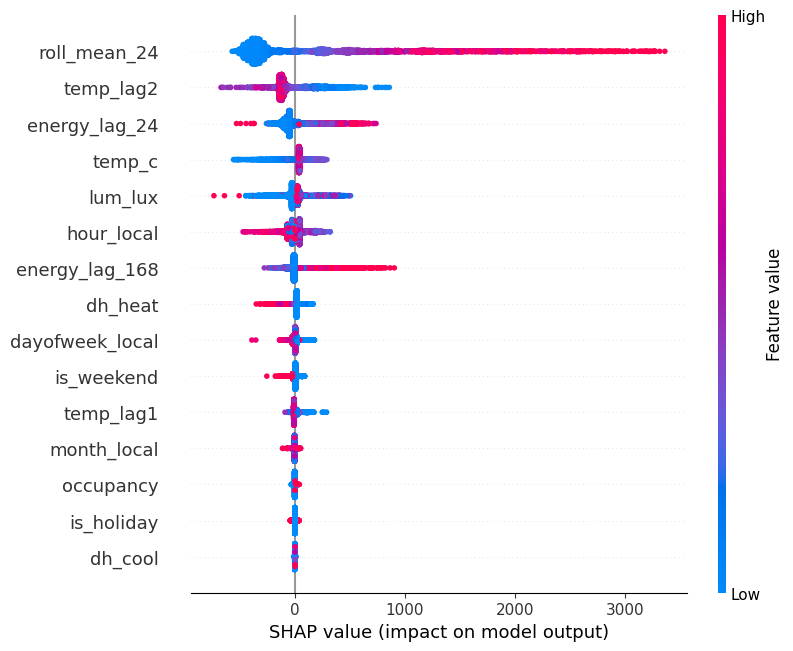

In [ ]:
shap.plots.beeswarm(shap_values_plugs, max_display=15)

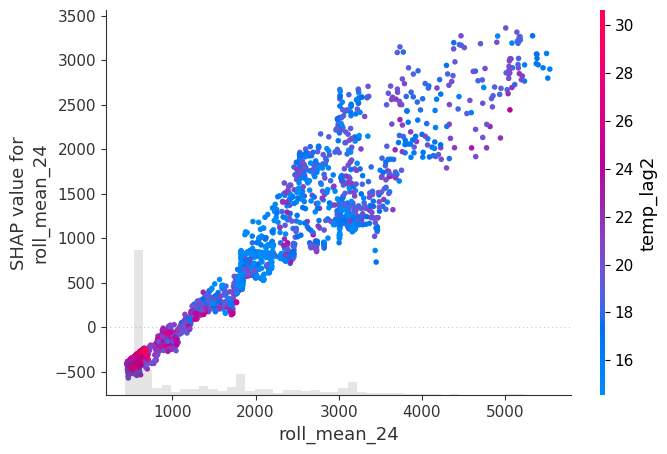

In [ ]:
shap.plots.scatter(
    shap_values_plugs[:, "roll_mean_24"],
    color=shap_values_plugs[:, "temp_lag2"]
)

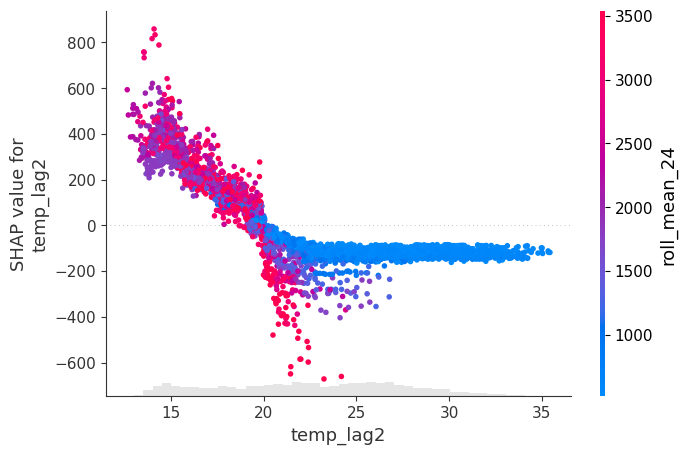

In [ ]:
shap.plots.scatter(
    shap_values_plugs[:, "temp_lag2"],
    color=shap_values_plugs[:, "roll_mean_24"]
)